In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('play_data.csv')
df = df.drop(columns = ['Unnamed: 0'])
df.columns

Index(['play_id', 'half_seconds_remaining', 'down', 'goal_to_go', 'ydstogo',
       'yardline_100', 'play_type', 'posteam_score', 'defteam_score', 'run'],
      dtype='object')

In [17]:
# preview data
df

,play_id,half_seconds_remaining,down,goal_to_go,ydstogo,yardline_100,play_type,posteam_score,defteam_score,run
0,63.0,1796.0,1.0,0,10.0,78.0,run,0.0,0.0,1
1,85.0,1758.0,2.0,0,7.0,75.0,pass,0.0,0.0,0
2,115.0,1720.0,1.0,0,10.0,64.0,pass,0.0,0.0,0
3,135.0,1677.0,2.0,0,21.0,75.0,run,0.0,0.0,1
4,166.0,1634.0,3.0,0,23.0,77.0,run,0.0,0.0,1
...,...,...,...,...,...,...,...,...,...,...
4685,4510.0,377.0,2.0,0,6.0,74.0,pass,17.0,17.0,0
4686,4570.0,321.0,1.0,0,10.0,47.0,run,17.0,17.0,1
4687,4632.0,298.0,2.0,0,6.0,43.0,pass,17.0,17.0,0
4688,4655.0,294.0,3.0,0,6.0,43.0,pass,17.0,17.0,0


In [18]:
# Goal: predict if a play is a run (1) or a pass (0) from the game situation 
X = df[['half_seconds_remaining', 'down', 'ydstogo', 'yardline_100', 'posteam_score', 'defteam_score']]
y = df['run']

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
# Random Forest = lots of decision trees that each vote, the majority wins
# Every tree sees a random sample of the plays AND a random handful of the columns, so no two trees look alike
# n_estimators = how many trees get a vote
# max_depth    = how big each tree is (None = as big as it wants)
# max_features = how many columns each split is allowed to look at
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n ", classification_report(y_test, y_pred, target_names=['Pass', 'Run']))

Random Forest Accuracy: 0.6716417910447762

Classification Report:
                precision    recall  f1-score   support

        Pass       0.68      0.79      0.73       535
         Run       0.65      0.51      0.57       403

    accuracy                           0.67       938
   macro avg       0.67      0.65      0.65       938
weighted avg       0.67      0.67      0.66       938



In [ ]:
# Did it overfit? 
print("Train Accuracy:", accuracy_score(y_train, model.predict(X_train)))
print("Test Accuracy: ", accuracy_score(y_test, y_pred))

Train Accuracy: 1.0
Test Accuracy:  0.6716417910447762


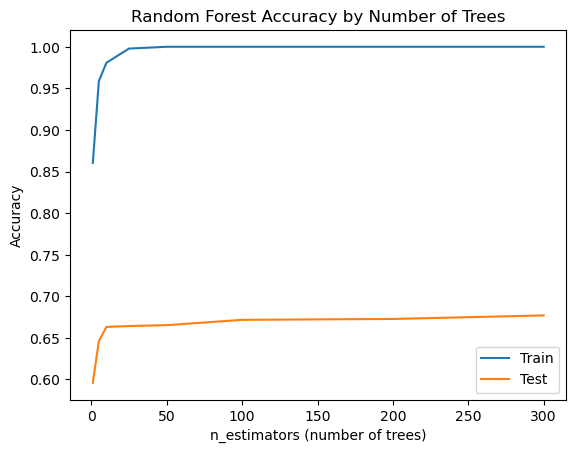

In [22]:
# How many trees do we need? Try a bunch and compare train vs test accuracy
# unlike K in KNN, more trees will not make the model overfit more, it just stops helping after a while
trees = [1, 5, 10, 25, 50, 100, 200, 300]
train_acc = []
test_acc = []

for n in trees:
    rf = RandomForestClassifier(n_estimators=n, random_state=42)
    rf.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, rf.predict(X_train)))
    test_acc.append(accuracy_score(y_test, rf.predict(X_test)))

plt.plot(trees, train_acc, label='Train')
plt.plot(trees, test_acc, label='Test')
plt.xlabel('n_estimators (number of trees)')
plt.ylabel('Accuracy')
plt.title('Random Forest Accuracy by Number of Trees')
plt.legend()
plt.show()

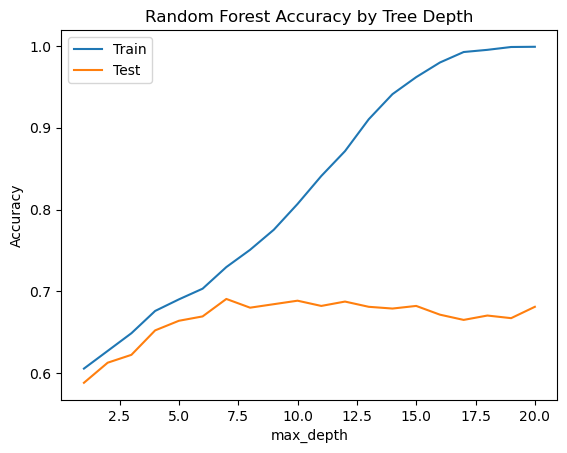

In [ ]:
# try a few max_depth values and compare train vs test
depths = range(1, 21)
train_acc = []
test_acc = []

for d in depths:
    rf = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=42)
    rf.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, rf.predict(X_train)))
    test_acc.append(accuracy_score(y_test, rf.predict(X_test)))

plt.plot(depths, train_acc, label='Train')
plt.plot(depths, test_acc, label='Test')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Random Forest Accuracy by Tree Depth')
plt.legend()
plt.show()

In [24]:
# Refit with the depth that did best on the test data
best_depth = list(depths)[test_acc.index(max(test_acc))]
print("Best max_depth:", best_depth)

model = RandomForestClassifier(n_estimators=100, max_depth=best_depth, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n ", classification_report(y_test, y_pred, target_names=['Pass', 'Run']))

Best max_depth: 7
Accuracy: 0.6908315565031983

Classification Report:
                precision    recall  f1-score   support

        Pass       0.71      0.78      0.74       535
         Run       0.66      0.57      0.61       403

    accuracy                           0.69       938
   macro avg       0.69      0.68      0.68       938
weighted avg       0.69      0.69      0.69       938



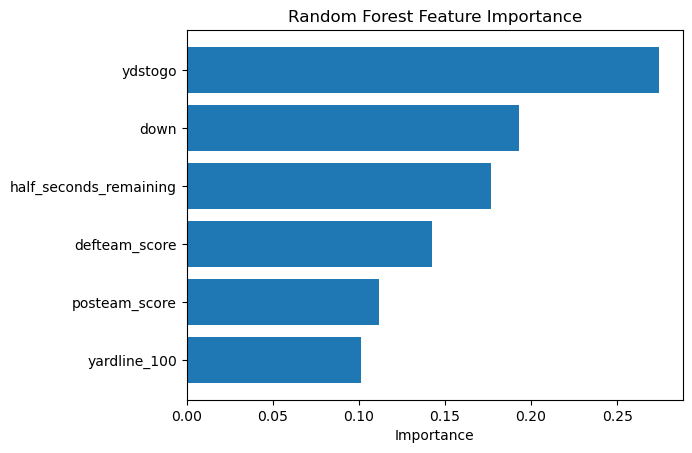

In [25]:
# Which columns did the forest lean on the most? Does this make sense for predicting run vs pass?
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values()

plt.barh(importance.index, importance.values)
plt.xlabel('Importance')
plt.title('Random Forest Feature Importance')
plt.show()

In [ ]:
# Predict a new play: 3rd & 1 on the opponent's 40, 5 minutes left in the half, tied 14-14
new_play = pd.DataFrame({
    'half_seconds_remaining': [300],
    'down': [3],
    'ydstogo': [1],
    'yardline_100': [40],
    'posteam_score': [14],
    'defteam_score': [14]
})

print("Prediction:", 'Run' if model.predict(new_play[X.columns])[0] == 1 else 'Pass')
print("Run probability:", model.predict_proba(new_play[X.columns])[0][1].round(2))

Prediction: Run
Run probability: 0.68


Trees voting Run:  74
Trees voting Pass: 26


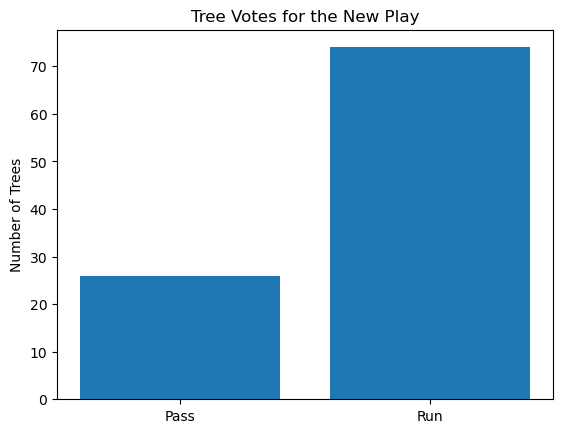

In [27]:
# How did each tree vote? The forest's probability is just the share of trees that said run
votes = [t.predict(new_play[X.columns].values)[0] for t in model.estimators_]

print("Trees voting Run: ", int(sum(votes)))
print("Trees voting Pass:", int(len(votes) - sum(votes)))

plt.bar(['Pass', 'Run'], [len(votes) - sum(votes), sum(votes)])
plt.ylabel('Number of Trees')
plt.title('Tree Votes for the New Play')
plt.show()